# PathSnap model 03: k-Nearest Neighbours

*Family: Instance-based*

**What every model in this project does.** For each GPS fix we already have a short list of *candidate* road arcs
(all arcs within 50 m, at least 5). Each (fix, candidate) pair is one row with 13 features (distance, heading
difference, …) and a label `y` = 1 if the candidate is the fix's true arc, else 0. The model learns
**P(candidate is the true arc | features)**. For each fix, the candidate with the highest probability is the
prediction. Every model notebook uses the same data, folds and metrics from `pathsnap_common.py`, so the numbers are
directly comparable.

**Metrics used below** (full definitions in the report):
- **Top-1 accuracy** (primary): share of fixes whose highest-probability candidate is the true arc.
- **Macro F1**: per trip, the F1-score of each road arc treated as a class, averaged over arcs (so short, rarely
  visited arcs count as much as long ones), then averaged over trips.
- **Log loss**: how good the probabilities are (lower is better); punishes confident mistakes.
- **Precision / recall / F1 / confusion matrix**: candidate level, "is this the true arc?" with threshold 0.5.
- **Route continuity**: share of consecutive fixes whose predicted arcs are the same or connected within 3 arcs.
- **Route F1**: length-weighted overlap between the set of predicted arcs and the reference route.

## 1. What the algorithm does

**k-Nearest Neighbours (kNN)** stores the training rows. To score a new (fix, candidate) row it finds the k most
similar training rows (Euclidean distance in the standardised feature space) and returns the (distance-weighted)
share of them that were true arcs. There is no training step beyond storing the data ("lazy learning").

## 2. Why we tried it for PathSnap, strengths and limitations

- It makes no assumption about the shape of the decision boundary, so it is a useful check on whether the
  candidate problem is "locally simple": a candidate that looks like past true arcs probably is one.
- **Strengths:** non-linear, no assumptions, easy to explain.
- **Limitations:** prediction is slow (every query searches the stored rows), so it cannot use all 1.8 M rows; it
  needs feature scaling (otherwise `arc_len` in metres would dominate `along_t` in 0–1); every feature counts
  equally in the distance, including weak ones; probabilities are coarse (a share of k neighbours).
- With `weights="distance"`, a training row is its own nearest neighbour at distance 0, so the **train** score is
  close to 100% by construction. For kNN the train/validation gap therefore over-states overfitting; the
  validation score is what matters.

### Hyperparameters (initial values) and training objective

| Hyperparameter | Initial value | Meaning |
|---|---|---|
| `n_neighbors` (k) | 50 | number of neighbours voting; larger = smoother probabilities |
| `weights` | distance | closer neighbours count more |
| `metric` | Euclidean (Minkowski p=2) | distance in the standardised feature space |
| `algorithm` | auto (KD-tree / ball tree) | spatial index used for the search |
| preprocessing | log1p + standardise, one-hot `conn_prev` | puts every feature on the same scale |
| `FRAC` | 0.05 | 5% of training fixes (≈ 70 k rows per fold) to keep prediction time manageable |


**Objective:** none. kNN has no loss function and no training phase; the "model" is the stored training sample.

### Setup: load the candidate tables

In [1]:
import sys, time, json
sys.path.insert(0, ".")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathsnap_common import *

train = load_partition("train")          # every candidate row of the 80 train trips
test = load_partition("student_test")    # every candidate row of the 10 student_test trips
print(f"train: {len(train):,} rows ({train.keep_train.sum():,} with reliable labels) | student_test: {len(test):,} rows")
print("features:", FEATURES)

train: 2,103,209 rows (1,801,387 with reliable labels) | student_test: 222,004 rows
features: ['dist', 'dist_rank', 'dist_gap', 'heading_diff', 'speed', 'along_t', 'arc_len', 'has_twin', 'junction_deg', 'n_cand20', 'n_cand50', 'nbr_dist', 'conn_prev']


### Model definition

In [2]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline

NAME, TITLE, FAMILY = "knn", "k-Nearest Neighbours", "Instance-based"
FRAC, SAVE_MODEL = 0.05, True
CONFIG = dict(n_neighbors=50, weights="distance", metric="euclidean",
              preprocessing="log1p+standardise, one-hot conn_prev", train_frac=FRAC)


def make_model():
    return make_pipeline(scaled_preprocessor(), KNeighborsClassifier(n_neighbors=50, weights="distance", n_jobs=8))

## 3. Cross-validation (GroupKFold by trip, 5 folds)

The 80 train trips are split into 5 groups of 16. Each fold trains on 64 trips and predicts the 16 held-out trips,
so the model is always scored on trips it has never seen (fixes of one trip are nearly identical, so mixing them
would inflate scores). Training uses a random `FRAC` share of the reliable-label fixes of the 64 trips (all
candidates of a chosen fix stay together); prediction covers every candidate of the held-out trips.
We also score the model on (a sample of) the fixes it was trained on: a large train/validation gap means
**overfitting**; low scores on both mean **underfitting**.

[knn] fold 1: train top-1 1.0000 | val top-1 0.8415 | val log loss 0.1083 | fit 0s


[knn] fold 2: train top-1 1.0000 | val top-1 0.8740 | val log loss 0.0813 | fit 0s


[knn] fold 3: train top-1 1.0000 | val top-1 0.8351 | val log loss 0.1018 | fit 0s


[knn] fold 4: train top-1 1.0000 | val top-1 0.8854 | val log loss 0.0662 | fit 0s


[knn] fold 5: train top-1 1.0000 | val top-1 0.8177 | val log loss 0.1201 | fit 0s


CV done in 902 s


,fold,train_rows,fit_s,train_top1,val_top1,train_logloss,val_logloss,val_macro_f1,val_precision,val_recall,val_f1,val_continuity,val_route_f1
0,1,71009,0.0753,1.0,0.8415,0.0,0.1083,0.6454,0.8451,0.8142,0.8294,0.9600,0.8350
1,2,72434,0.0983,1.0,0.8740,0.0,0.0813,0.7434,0.8682,0.8312,0.8493,0.9509,0.8993
2,3,70822,0.0789,1.0,0.8351,0.0,0.1018,0.6709,0.8427,0.8016,0.8216,0.9766,0.8614
3,4,72336,0.1142,1.0,0.8854,0.0,0.0662,0.7277,0.8849,0.8553,0.8699,0.9733,0.8953
4,5,72682,0.0743,1.0,0.8177,0.0,0.1201,0.6384,0.8297,0.7830,0.8057,0.9798,0.8253


mean ± std  val top-1 85.07% ± 2.81% | val macro F1 0.6852 ± 0.0479 | val log loss 0.0956


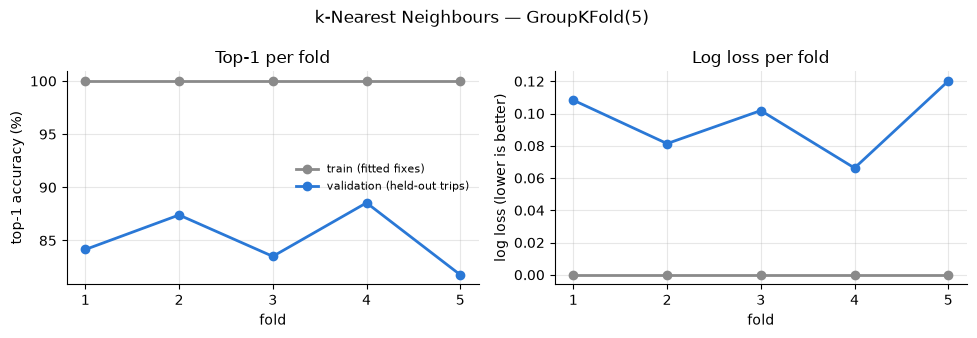

In [3]:
t0 = time.time()
cv, oof, cv_models = run_cv(make_model, train, FRAC, label=NAME, train_eval_fixes=5_000)
print(f"CV done in {time.time() - t0:.0f} s")
show = ["fold", "train_rows", "fit_s", "train_top1", "val_top1", "train_logloss", "val_logloss", "val_macro_f1",
        "val_precision", "val_recall", "val_f1", "val_continuity", "val_route_f1"]
display(cv[show].round(4))
print("mean ± std  val top-1 {:.2%} ± {:.2%} | val macro F1 {:.4f} ± {:.4f} | val log loss {:.4f}".format(
    cv.val_top1.mean(), cv.val_top1.std(), cv.val_macro_f1.mean(), cv.val_macro_f1.std(), cv.val_logloss.mean()))
fig = plot_cv(cv, TITLE + " — GroupKFold(5)")
(OUT_DIR / NAME).mkdir(parents=True, exist_ok=True)
fig.savefig(OUT_DIR / NAME / "fig_cv.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Final fit on all 80 train trips and evaluation on student_test

Refit with the same recipe on the reliable-label fixes of all 80 train trips, then score every candidate of the 10
student_test trips. student_test is used only for this development-stage comparison, never for training.
**Inference time** is the time `predict_proba` takes for all student_test candidates, per 1 000 GPS fixes
(features are already computed; feature building is the same for every model).

,student_test
top1,0.8637
top1_all,0.8336
macro_f1,0.7026
logloss,0.0772
precision,0.8655
recall,0.8352
f1,0.8501
continuity,0.9725
route_f1,0.8989
fit_s,0.0935


,trip,n_fix,top1,macro_f1,continuity,route_f1
0,00000000,2503,0.9277,0.6831,0.9884,0.9461
1,00000007,1354,0.9787,0.9305,0.9993,0.9840
2,00000009,1049,0.8255,0.7110,0.9695,0.8642
3,00000040,2995,0.9293,0.7646,0.9937,0.9266
4,00000052,262,0.9198,0.7556,0.9693,0.9358
5,00000056,3958,0.8603,0.7455,0.9330,0.9011
6,00000065,768,0.8164,0.6382,0.9713,0.8991
7,00000076,1486,0.8183,0.5428,0.9481,0.8513
8,00000077,3911,0.7563,0.5690,0.9928,0.7863
9,00000091,874,0.8307,0.6853,0.9485,0.8943


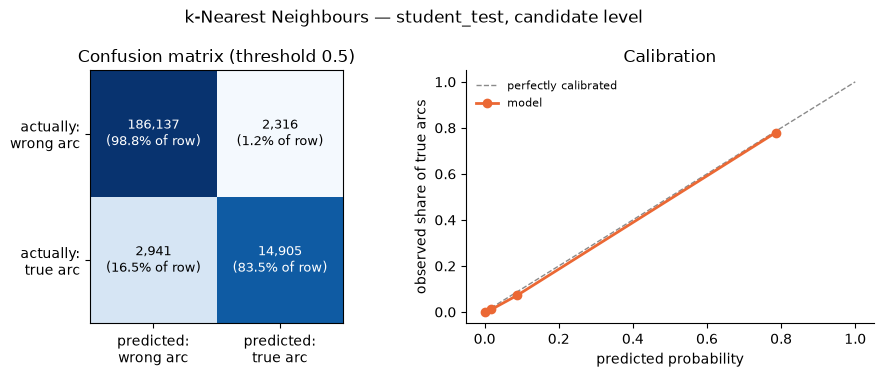

In [4]:
final_model, p_test, test_res, test_preds = fit_and_test(make_model, train, test, FRAC)
keys = ["top1", "top1_all", "macro_f1", "logloss", "precision", "recall", "f1", "continuity", "route_f1",
        "fit_s", "predict_ms_per_1k_fixes"]
display(pd.Series({k: test_res[k] for k in keys}).to_frame("student_test").round(4))
display(pd.DataFrame(test_res["per_trip"]).assign(trip=lambda d: [trips("student_test")[t] for t in d.tidx])
        .assign(top1=lambda d: d.correct_kept / d.n_kept)[["trip", "n_fix", "top1", "macro_f1", "continuity", "route_f1"]].round(4))
fig = plot_confusion_and_calibration(test, p_test, TITLE)
fig.savefig(OUT_DIR / NAME / "fig_confusion_calibration.png", dpi=150, bbox_inches="tight")
plt.show()

## Save results

Writes `results/<model>/results.json` (config, CV mean/std, student_test metrics), the per-fold table, per-trip student_test table, out-of-fold probabilities (used by the comparison and HMM notebooks) and the fitted model.

In [5]:
summary = save_results(NAME, FAMILY, CONFIG, cv, test_res, model=final_model if SAVE_MODEL else None,
                       oof=oof, p_test=p_test)
print(json.dumps({k: summary[k] for k in ["name", "family", "config"]}, indent=1))
print("saved to", OUT_DIR / NAME)

{
 "name": "knn",
 "family": "Instance-based",
 "config": {
  "n_neighbors": 50,
  "weights": "distance",
  "metric": "euclidean",
  "preprocessing": "log1p+standardise, one-hot conn_prev",
  "train_frac": 0.05
 }
}
saved to /home/av8/Documents/ML/Hackathon/results/knn
